In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [3]:
import sys
print(sys.executable)

d:\ML Projects\Real Time Fraud Detection System\.venv\Scripts\python.exe


In [4]:
df=pd.read_csv("../data/creditcard.csv")
print(df.shape)

(284807, 31)


In [5]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [7]:
print(df.isnull().sum().sum())   #Missing Values

0


In [8]:
#Duplicate Rows
print(df.duplicated().sum())

1081


In [9]:
sns.set_theme(style="whitegrid")

In [10]:
df[["Time","Amount","Class"]].describe()

,Time,Amount,Class
count,284807.000000,284807.000000,284807.000000
mean,94813.859575,88.349619,0.001727
std,47488.145955,250.120109,0.041527
min,0.000000,0.000000,0.000000
25%,54201.500000,5.600000,0.000000
50%,84692.000000,22.000000,0.000000
75%,139320.500000,77.165000,0.000000
max,172792.000000,25691.160000,1.000000


Class
0    284315
1       492
Name: count, dtype: int64
Fraude rate 0.1727%
Always predicting 'legit' gives 99.83% accuracy and catches 0 frauds


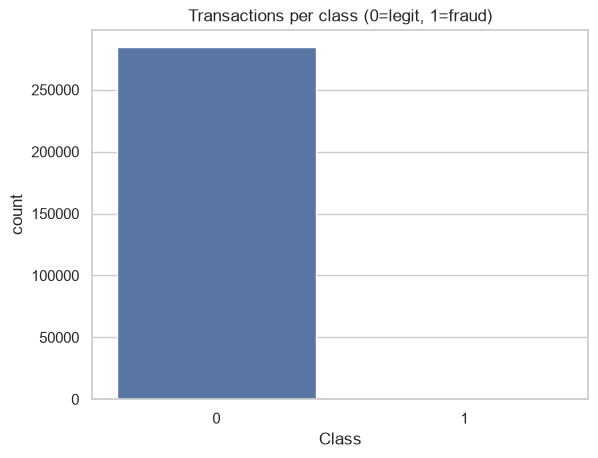

In [11]:
#Class Imbalance 

counts=df["Class"].value_counts()
rate=df["Class"].mean()
print(counts)

print(f"Fraude rate {rate:.4%}")
print(f"Always predicting 'legit' gives {1-rate:.2%} accuracy and catches 0 frauds")

sns.countplot(data=df,x="Class",hue="Class",legend=False)
plt.title("Transactions per class (0=legit, 1=fraud)")
plt.show()

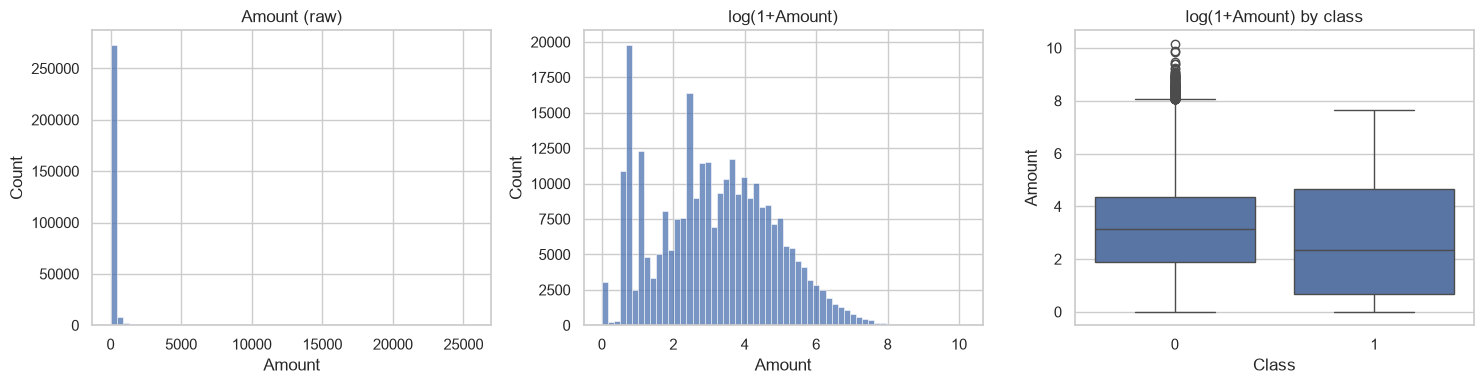

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [12]:
fig , ax =plt.subplots(1,3,figsize=(15,4))
sns.histplot(df["Amount"],bins=60,ax=ax[0])
ax[0].set_title("Amount (raw)")

sns.histplot(np.log1p(df["Amount"]),bins=60,ax=ax[1])
ax[1].set_title("log(1+Amount)")

sns.boxplot(data=df,x="Class",y=np.log1p(df["Amount"]),ax=ax[2])
ax[2].set_title("log(1+Amount) by class")

plt.tight_layout()
plt.show()

print(df.groupby("Class")["Amount"].describe())

#OBSERVATIONS SO FAR 
findings: Amount feature

Right-skewed distribution

Extreme transaction values

Fraud median lower than legitimate

Fraud mean higher than legitimate

Amount alone separates fraud

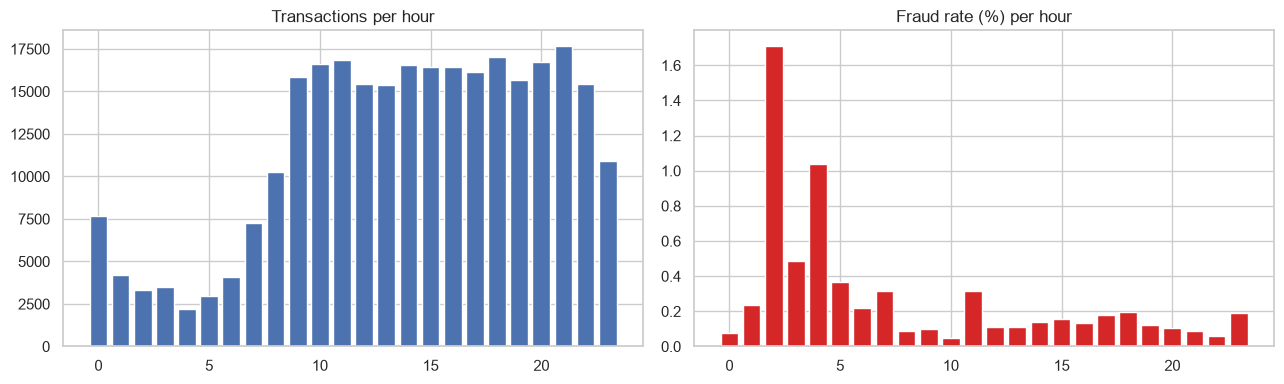

hour,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0
n,7695.000,4220.000,3328.000,3492.000,2209.000,2990.000,4101.000,7243.000,10276.000,15838.000,...,16570.000,16461.000,16453.000,16166.000,17039.000,15649.000,16756.000,17703.00,15441.000,10938.000
frauds,6.000,10.000,57.000,17.000,23.000,11.000,9.000,23.000,9.000,16.000,...,23.000,26.000,22.000,29.000,33.000,19.000,18.000,16.00,9.000,21.000
fraud_rate_%,0.078,0.237,1.713,0.487,1.041,0.368,0.219,0.318,0.088,0.101,...,0.139,0.158,0.134,0.179,0.194,0.121,0.107,0.09,0.058,0.192


In [13]:
# Time and fraud rate by hour
# Time is seconds since the first transaction; the data covers about 2 days
df["hour"] = (df["Time"] // 3600) % 24
by_hour = df.groupby("hour").agg(n=("Class", "size"), frauds=("Class", "sum"))
by_hour["fraud_rate_%"] = by_hour["frauds"] / by_hour["n"] * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(by_hour.index, by_hour["n"])
ax[0].set_title("Transactions per hour")
ax[1].bar(by_hour.index, by_hour["fraud_rate_%"], color="tab:red")
ax[1].set_title("Fraud rate (%) per hour")
plt.tight_layout()
plt.show()
by_hour.round(3).T    # check n: hours with few transactions give noisy rates

In [14]:
by_hour.sort_values("fraud_rate_%", ascending=False)[
    ["n", "frauds", "fraud_rate_%"]
]

,n,frauds,fraud_rate_%
hour,,,
2.0,3328,57,1.712740
4.0,2209,23,1.041195
3.0,3492,17,0.486827
5.0,2990,11,0.367893
7.0,7243,23,0.317548
11.0,16856,53,0.314428
1.0,4220,10,0.236967
6.0,4101,9,0.219459
18.0,17039,33,0.193673


#Conclusion 

Highest fraud rate -Hour 2

Lowest fraud rate-Hour 10

Highest fraud count-Hour 2 (57)

Highest transaction volume-Hour 21 (17,703)



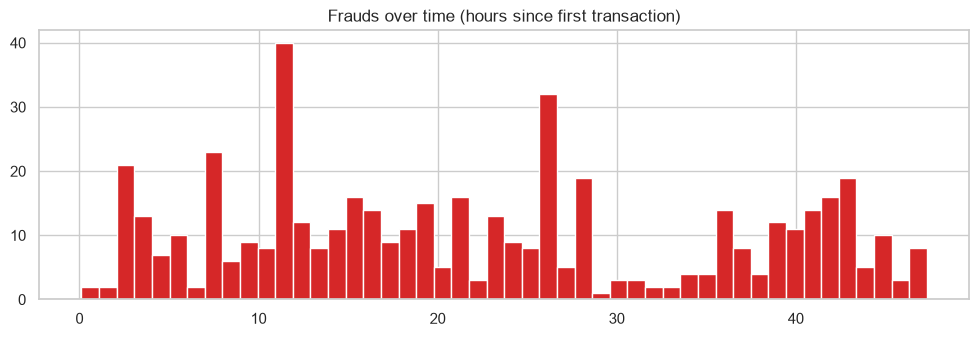

train: 199,364 rows | 384 frauds | rate 0.1926%
valid: 42,721 rows | 56 frauds | rate 0.1311%
test: 42,722 rows | 52 frauds | rate 0.1217%


In [15]:
# frauds over time + how a 70/15/15 time split would look
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.hist(df.loc[df["Class"] == 1, "Time"] / 3600, bins=48, color="tab:red")
ax.set_title("Frauds over time (hours since first transaction)")
plt.show()

d = df.sort_values("Time").reset_index(drop=True)
i1, i2 = int(len(d) * 0.70), int(len(d) * 0.85)
for name, part in {"train": d[:i1], "valid": d[i1:i2], "test": d[i2:]}.items():
    print(f"{name}: {len(part):,} rows | {int(part['Class'].sum())} frauds | rate {part['Class'].mean():.4%}")

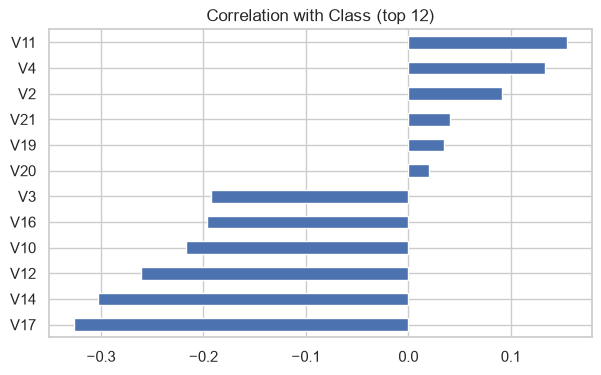

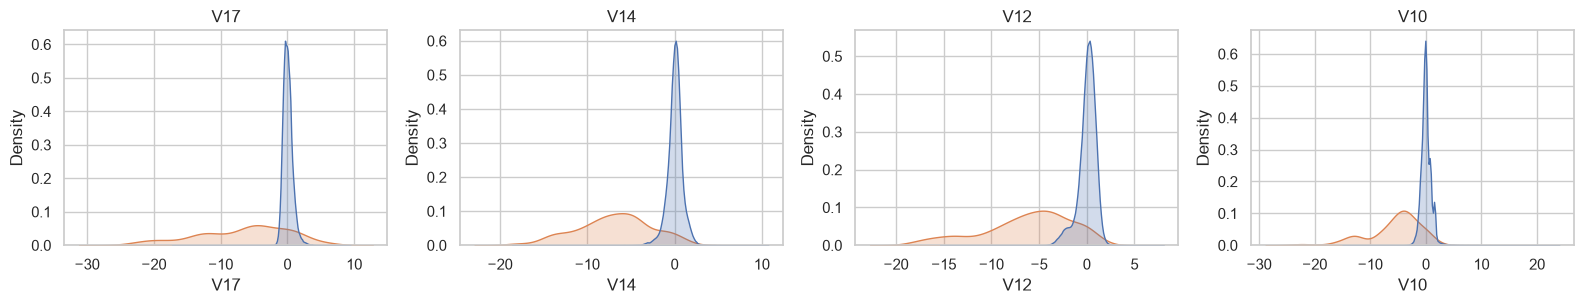

Strongest signals: ['V17', 'V14', 'V12', 'V10']


In [16]:
# which features separate fraud from legit?
feat = [c for c in df.columns if c.startswith("V")] + ["Amount"]
corr = df[feat + ["Class"]].corr()["Class"].drop("Class").sort_values()
top = pd.concat([corr.head(6), corr.tail(6)])
top.plot(kind="barh", figsize=(7, 4), title="Correlation with Class (top 12)")
plt.show()

best = corr.abs().sort_values(ascending=False).head(4).index
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for a, f in zip(axes, best):
    sns.kdeplot(data=df, x=f, hue="Class", common_norm=False, fill=True, ax=a, legend=False)
    a.set_title(f)
plt.tight_layout()
plt.show()
print("Strongest signals:", list(best))

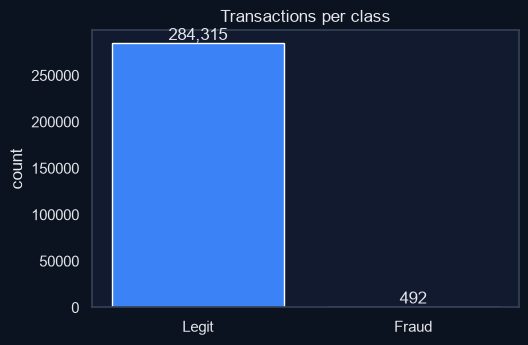

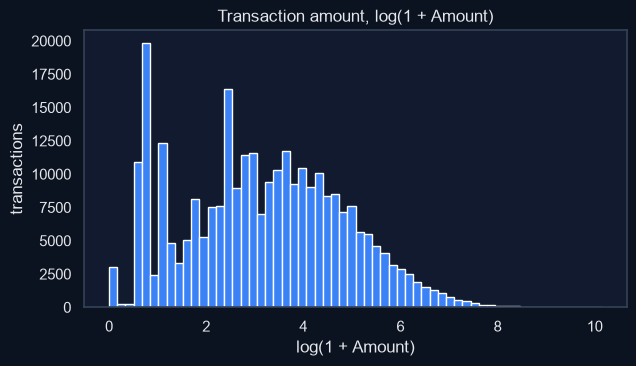

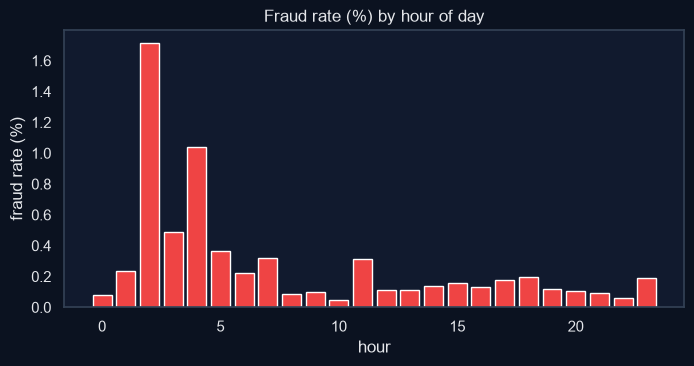

In [17]:
from pathlib import Path

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

DARK = {"figure.facecolor": "#0B1220", "axes.facecolor": "#111A2E",
        "savefig.facecolor": "#0B1220", "text.color": "#E5E7EB",
        "axes.labelcolor": "#E5E7EB", "xtick.color": "#E5E7EB",
        "ytick.color": "#E5E7EB", "axes.edgecolor": "#334155",
        "axes.titlecolor": "#E5E7EB", "axes.grid": False}

# 1. Class balance
with plt.rc_context(DARK):
    counts = df["Class"].value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    ax.bar(["Legit", "Fraud"], counts.values, color=["#3B82F6", "#EF4444"])
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom")
    ax.set_title("Transactions per class")
    ax.set_ylabel("count")
    fig.savefig(FIG / "01_class_balance.png", bbox_inches="tight", dpi=150)
    plt.show()

# 2. Amount on a log scale
with plt.rc_context(DARK):
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.hist(np.log1p(df["Amount"]), bins=60, color="#3B82F6")
    ax.set_title("Transaction amount, log(1 + Amount)")
    ax.set_xlabel("log(1 + Amount)")
    ax.set_ylabel("transactions")
    fig.savefig(FIG / "02_amount.png", bbox_inches="tight", dpi=150)
    plt.show()

# 3. Fraud rate by hour of day
with plt.rc_context(DARK):
    hour = (df["Time"] // 3600) % 24
    rate = df.groupby(hour)["Class"].mean() * 100
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.bar(rate.index, rate.values, color="#EF4444")
    ax.set_title("Fraud rate (%) by hour of day")
    ax.set_xlabel("hour")
    ax.set_ylabel("fraud rate (%)")
    fig.savefig(FIG / "03_hour.png", bbox_inches="tight", dpi=150)
    plt.show()